# Long-tailed images: one model, two test sets, two very different accuracies

A classifier trained on a long-tailed image dataset can be evaluated on a validation set that has the
same long tail as the training data, or on a balanced test set. The same model gets an accuracy near
0.92 on one and near 0.66 on the other. This notebook uses the predictions of ResNet-32 models trained on
CIFAR-10-LT to show why, which measures change with the class prior and which do not, and what that means
for comparing a baseline with a method designed for imbalance.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aggmetrics import IndicatorMatrix, pareto_dominance

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## The models and the data

CIFAR-10-LT keeps 4490 training images of class 0 and only 42 of class 9: an imbalance ratio of 100.
Two ResNet-32 models were trained for 200 epochs, five seeds each: one with the usual cross-entropy
(`ce`) and one with the logit-adjusted loss (`logit_adj`, Menon et al., 2021), which accounts for the
class prior in training. The file in the repository holds the **predictions** of those models and the
true labels, on two sets:

- a long-tailed **validation** split, drawn from the training distribution (1241 images, a new draw for
  each seed);
- the standard CIFAR-10 **test** set, which is balanced: 1000 images per class.

Images and logits are not included; the origin of the models and the citations are in the README next to
the file.

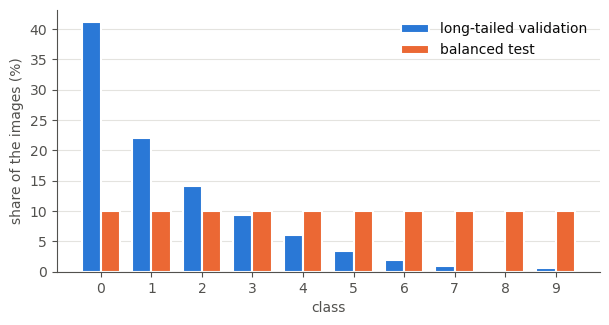

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/cifar10lt/predictions.npz"
local = Path("../data/cifar10lt/predictions.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
z = np.load(source)

loss, seed, y_test = z["loss"], z["seed"], z["y_test"].astype(int)

def im_of(name, s, split):
    i = np.flatnonzero((loss == name) & (seed == s))[0]
    y = y_test if split == "test" else z["y_val"][i].astype(int)
    return IndicatorMatrix(y, z["pred_" + split][i].astype(int), task="multiclass", n_classes=10)

runs = {(name, s, split): im_of(name, s, split)
        for name in ("ce", "logit_adj") for s in range(5) for split in ("val", "test")}

val_share = np.bincount(z["y_val"][0].astype(int), minlength=10) / z["y_val"].shape[1]
test_share = np.bincount(y_test, minlength=10) / len(y_test)

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(10)
w = 0.38
ax.bar(x - w / 2, 100 * val_share, w, color=BLUE, edgecolor="white", linewidth=1.5, label="long-tailed validation")
ax.bar(x + w / 2, 100 * test_share, w, color=ORANGE, edgecolor="white", linewidth=1.5, label="balanced test")
ax.set_xticks(x)
ax.set_xlabel("class")
ax.set_ylabel("share of the images (%)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.show()

## The same model, two accuracies

Take the cross-entropy model of seed 0:

In [4]:
ce_val, ce_test = runs[("ce", 0, "val")], runs[("ce", 0, "test")]
pd.DataFrame({
    "long-tailed validation": {"accuracy": ce_val.accuracy(), "macro-recall": ce_val.compute("recall", "macro")},
    "balanced test": {"accuracy": ce_test.accuracy(), "macro-recall": ce_test.compute("recall", "macro")},
}).round(3)

,long-tailed validation,balanced test
accuracy,0.917,0.65
macro-recall,0.699,0.65


The accuracy goes from 0.92 on the validation split to 0.65 on the test set. Nothing about the model
changed. Class 0 is 41% of the validation images and the model gets almost all of them right, so accuracy
there is mostly the accuracy on the head classes. On the test set every class counts for a tenth.

The two sets also expose a relation that is easy to check. On a set with the same number of examples in
every class, accuracy and macro-recall are the same number, because accuracy is then the average of the
per-class recalls. On the long-tailed set they are far apart:

In [5]:
rows = []
for (name, s, split), im in runs.items():
    rows.append(dict(model=name, seed=s, split=split, accuracy=im.accuracy(),
                     macro_recall=im.compute("recall", "macro")))
metrics = pd.DataFrame(rows)
metrics["gap"] = metrics.accuracy - metrics.macro_recall

test_rows = metrics[metrics.split == "test"]
assert np.allclose(test_rows.accuracy, test_rows.macro_recall, atol=1e-12)
print("balanced test:  accuracy equals macro-recall in all 10 runs (largest difference "
      f"{float(test_rows.gap.abs().max()):.1e})")
print("long-tailed validation: mean gap between accuracy and macro-recall =",
      round(float(metrics[metrics.split == "val"].gap.mean()), 3))

balanced test:  accuracy equals macro-recall in all 10 runs (largest difference 1.1e-16)
long-tailed validation: mean gap between accuracy and macro-recall = 0.204


## What moves with the prior, and what does not

Recall of a class asks, among the images of that class, how many were found. It does not depend on how
many images the other classes have, so in expectation it is the same on any test set drawn from the same
class-conditional distributions. Precision and specificity ask about the images *predicted* as a class or
*not in* the class, and those depend on the mix of the other classes.

Recall per class, averaged over the five seeds of the cross-entropy models:

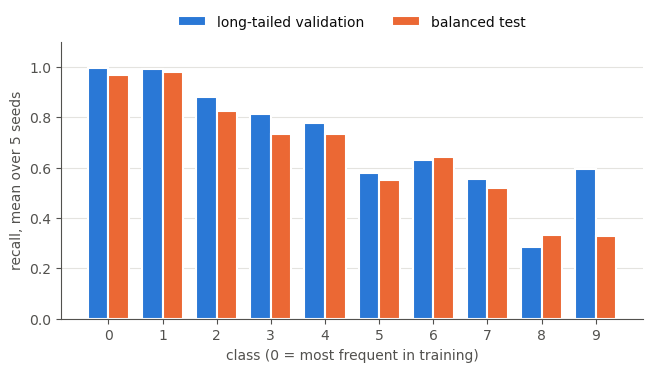

largest difference in recall, classes 0-4: 0.079
largest difference in recall, class 9    : 0.264


In [6]:
def mean_recall(name, split):
    return np.mean([runs[(name, s, split)].parts("recall", "macro") for s in range(5)], axis=0)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(10)
w = 0.38
ax.bar(x - w / 2, mean_recall("ce", "val"), w, color=BLUE, edgecolor="white", linewidth=1.5,
       label="long-tailed validation")
ax.bar(x + w / 2, mean_recall("ce", "test"), w, color=ORANGE, edgecolor="white", linewidth=1.5,
       label="balanced test")
ax.set_xticks(x)
ax.set_xlabel("class (0 = most frequent in training)")
ax.set_ylabel("recall, mean over 5 seeds")
ax.set_ylim(0, 1.1)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.show()

diff = np.abs(mean_recall("ce", "val") - mean_recall("ce", "test"))
print("largest difference in recall, classes 0-4:", round(float(diff[:5].max()), 3))
print("largest difference in recall, class 9    :", round(float(diff[9]), 3))

The recalls are close for the frequent classes (within 0.08) but not identical, and the validation set
is a poor guide for the rare ones: each seed has between 2 and 10 validation images of classes 8 and 9, so
a single image moves their recall by 10 to 50 points. Part of the remaining difference may also come from
the validation images being drawn from the CIFAR training split and the test images from the test split.

Precision and specificity, on the other hand, move with the class mix. Averaged over classes and seeds:

In [7]:
def mean_over_seeds(name, split, measure):
    return np.mean([runs[(name, s, split)].compute(measure, "macro") for s in range(5)])

pd.DataFrame({
    f"{name}": {f"{split} {measure}": mean_over_seeds(name, split, measure)
                for split in ("val", "test") for measure in ("precision", "specificity")}
    for name in ("ce", "logit_adj")
}).round(3)

,ce,logit_adj
val precision,0.845,0.763
val specificity,0.990,0.990
test precision,0.755,0.760
test specificity,0.962,0.968


For the cross-entropy models, macro-precision falls from 0.84 on the validation split to 0.75 on the test
set, and macro-specificity from 0.99 to 0.96. Most of the negatives of any class in the long-tailed set are
head images, which the model classifies well. The logit-adjusted models are nearly the same on both for precision (0.76 and
0.76), which is a reminder that the size of the effect depends on the model, not only on the measure.

## Comparing a baseline with a method for imbalance

Which of the two training losses is better? Mean and standard deviation over the five seeds, on each set:

In [8]:
summary = (metrics.groupby(["split", "model"])[["accuracy", "macro_recall"]]
           .agg(["mean", "std"]).round(4))
summary

accuracy         macro_recall        
                    mean     std         mean     std
split model                                          
test  ce          0.6611  0.0085       0.6611  0.0085
      logit_adj   0.7090  0.0062       0.7090  0.0062
val   ce          0.9186  0.0041       0.7096  0.0198
      logit_adj   0.9138  0.0066       0.7140  0.0614

On the long-tailed validation split the two are indistinguishable: accuracy 0.919 (cross-entropy) against
0.914 (logit adjustment), with standard deviations of 0.004 and 0.007 across seeds, and macro-recall of 0.710
against 0.714, with standard deviations of 0.020 and 0.061. The macro measures are very noisy there, for the
reason above. On the balanced test set the difference is large and consistent:

In [9]:
test_acc = metrics[metrics.split == "test"].pivot(index="seed", columns="model", values="accuracy")
print(test_acc.round(4).to_string())
assert test_acc["logit_adj"].min() > test_acc["ce"].max()
print("\nevery logit-adjusted run is above every cross-entropy run on the test set:",
      round(float(test_acc["logit_adj"].min()), 4), ">", round(float(test_acc["ce"].max()), 4))

model      ce  logit_adj
seed                    
0      0.6498     0.7127
1      0.6619     0.7036
2      0.6590     0.7132
3      0.6736     0.7146
4      0.6614     0.7010

every logit-adjusted run is above every cross-entropy run on the test set: 0.701 > 0.6736


So a validation set with the long tail cannot tell these two methods apart, while the balanced test set
ranks them in every seed. The reason is visible in the per-class recall on the test set:

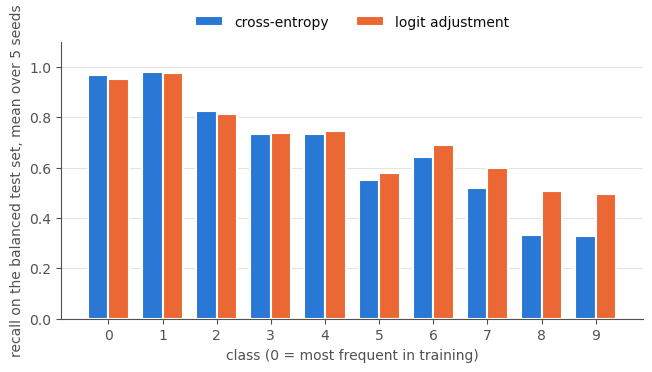

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(x - w / 2, mean_recall("ce", "test"), w, color=BLUE, edgecolor="white", linewidth=1.5, label="cross-entropy")
ax.bar(x + w / 2, mean_recall("logit_adj", "test"), w, color=ORANGE, edgecolor="white", linewidth=1.5,
       label="logit adjustment")
ax.set_xticks(x)
ax.set_xlabel("class (0 = most frequent in training)")
ax.set_ylabel("recall on the balanced test set, mean over 5 seeds")
ax.set_ylim(0, 1.1)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.show()

Logit adjustment gives up a little on the head (class 0: 0.951 against 0.965) and gains a lot on the tail
(classes 8 and 9: about 0.50 against 0.33). Accuracy on the long-tailed set weights class 0 by 41% and
each of the two rarest classes by under 1%, so it barely sees the gain. The test set weights them equally.

Because the head loses a little, the two models are not ordered on every class, and
`pareto_dominance` says so for the first seed:

In [11]:
pareto_dominance(runs[("ce", 0, "test")], runs[("logit_adj", 0, "test")])

'incomparable'

## What to report

- State the **class prior of the evaluation set** next to the number. An accuracy of 0.92 and an accuracy of
  0.66 can describe the same model.
- For a long-tailed problem, report **per-class recall** (with the number of examples) and the **macro-recall**
  on a balanced test set. On such a set accuracy and macro-recall are the same number; on a long-tailed one
  they are not, and the gap measures how much the head dominates.
- Treat **macro measures on a small long-tailed validation set as noisy**: a few images decide the rare classes.
  Compare methods with several seeds and look at the spread.
- Remember that precision and specificity change with the class mix, so they should not be carried from one
  test distribution to another.
- When two methods trade head for tail, `pareto_dominance` returns `'incomparable'`, and the choice depends
  on which classes matter.

Next: thresholds and degenerate optima, soft labels, and custom measures.